# TASK 1 - Preprocessing the textual Data

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [2]:
!pip install nltk
!pip install contractions
!pip install transformers

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import re
import string
import nltk
import contractions
import csv
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import RegexpTokenizer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib import cm
import torch
import gc
from transformers import BertTokenizer, BertForSequenceClassification, DistilBertTokenizerFast, DistilBertForSequenceClassification,RobertaTokenizerFast, RobertaForSequenceClassification, Trainer, TrainingArguments
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.decomposition import TruncatedSVD
from sklearn.decomposition import PCA

In [4]:
# Download NLTK asset
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to /Users/hashi/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /Users/hashi/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /Users/hashi/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to /Users/hashi/nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

In [5]:
df = pd.read_csv("../data/yelp_reviews_dataset.txt", sep="\t", header=None, names=["text", "label"])
original_texts = df['text'].copy()
df.head()

,text,label
0,Wow... Loved this place.,1
1,Crust is not good.,0
2,Not tasty and the texture was just nasty.,0
3,Stopped by during the late May bank holiday of...,1
4,The selection on the menu was great and so wer...,1


In [6]:
df.tail()

,text,label
995,I think food should have flavor and texture an...,0
996,Appetite instantly gone.,0
997,Overall I was not impressed and would not go b...,0
998,"The whole experience was underwhelming, and I ...",0
999,"Then, as if I hadn't wasted enough of my life ...",0


In [7]:
df.shape

(1000, 2)

In [8]:
df.columns

Index(['text', 'label'], dtype='object')

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   text    1000 non-null   object
 1   label   1000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 15.8+ KB


In [10]:
df.describe()

,label
count,1000.00000
mean,0.50000
std,0.50025
min,0.00000
25%,0.00000
50%,0.50000
75%,1.00000
max,1.00000


In [11]:
df.describe(include='object')

,text
count,1000
unique,996
top,I would not recommend this place.
freq,2


In [12]:
df.isnull().sum()

text     0
label    0
dtype: int64

In [13]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()
tokenizer = RegexpTokenizer(r'\w+')

In [14]:
# Utility function to format output
def print_formatted_output(title, reviews, figure_label):
    print(f"\n--- {title} ---")
    for i, review in enumerate(reviews[:5]):
        print(f"Review {i + 1}: {review}")

# Step 1: Expand Contractions (extra step 1)
def expand_contractions(texts):
    return texts.apply(lambda x: contractions.fix(x))

# Step 2: Lowercasing
def lowercase_reviews(texts):
    return texts.str.lower()

# Step 3: Remove Punctuation
def remove_punctuation(texts):
    return texts.apply(lambda x: x.translate(str.maketrans('', '', string.punctuation)))

# Step 4: Remove Numbers
def remove_numbers(texts):
    return texts.apply(lambda x: re.sub(r'\d+', '', x))

# Step 5: Tokenization
def tokenize_texts(texts):
    return texts.apply(lambda x: tokenizer.tokenize(x))

# Step 6: Remove Stopwords
def remove_stopwords(token_lists):
    return token_lists.apply(lambda tokens: [word for word in tokens if word not in stop_words])

# Step 7: Lemmatization
def lemmatize_tokens(token_lists):
    return token_lists.apply(lambda tokens: [lemmatizer.lemmatize(word) for word in tokens])

# Step 8: Remove Extra Whitespace (extra step 2)
def remove_extra_whitespace(text_list):
    return text_list.apply(lambda x: re.sub(r'\s+', ' ', x).strip())

# Run and display each step
expanded = expand_contractions(original_texts)
print_formatted_output("After Expanding Contractions", expanded, 1)

lower = lowercase_reviews(expanded)
print_formatted_output("After Converting to Lowercase", lower, 2)

no_punct = remove_punctuation(lower)
print_formatted_output("After Removing Punctuation", no_punct, 3)

no_numbers = remove_numbers(no_punct)
print_formatted_output("After Removing Numbers", no_numbers, 4)

tokenized = tokenize_texts(no_numbers)
tokenized_display = [' '.join(tokens) for tokens in tokenized]
print_formatted_output("After Tokenization", tokenized_display, 5)

no_stop = remove_stopwords(tokenized)
no_stop_display = [' '.join(tokens) for tokens in no_stop]
print_formatted_output("After Removing Stop Words", no_stop_display, 6)

lemmatized = lemmatize_tokens(no_stop)
lemmatized_display = pd.Series([' '.join(tokens) for tokens in lemmatized])
print_formatted_output("After Lemmatization", lemmatized_display, 7)

# Step 9 – Apply whitespace cleanup
final_cleaned = remove_extra_whitespace(lemmatized_display)
print_formatted_output("After Removing Extra Whitespace", final_cleaned, 8)

# Final Cleaned Text
print_formatted_output("Final Cleaned Text", final_cleaned, 9)



--- After Expanding Contractions ---
Review 1: Wow... Loved this place.
Review 2: Crust is not good.
Review 3: Not tasty and the texture was just nasty.
Review 4: Stopped by during the late May bank holiday off Rick Steve recommendation and loved it.
Review 5: The selection on the menu was great and so were the prices.

--- After Converting to Lowercase ---
Review 1: wow... loved this place.
Review 2: crust is not good.
Review 3: not tasty and the texture was just nasty.
Review 4: stopped by during the late may bank holiday off rick steve recommendation and loved it.
Review 5: the selection on the menu was great and so were the prices.

--- After Removing Punctuation ---
Review 1: wow loved this place
Review 2: crust is not good
Review 3: not tasty and the texture was just nasty
Review 4: stopped by during the late may bank holiday off rick steve recommendation and loved it
Review 5: the selection on the menu was great and so were the prices

--- After Removing Numbers ---
Review 1: w

# TASK 2 - Using Bag of Words and Perform 5 Classification Algorithm

### Vectorize Final Cleaned Text

In [15]:
vectorizer = CountVectorizer()
X = vectorizer.fit_transform(final_cleaned)
y = df['label']

### Train-Test Split

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Define Default Models

In [17]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Naive Bayes": MultinomialNB(),
    "XGBoost": XGBClassifier(eval_metric='logloss')
}

results = {}

### Train and Evaluate Default Models


 Logistic Regression Classification Report
----------------------------------------
              precision    recall  f1-score   support

           0       0.72      0.84      0.78        96
           1       0.83      0.70      0.76       104

    accuracy                           0.77       200
   macro avg       0.78      0.77      0.77       200
weighted avg       0.78      0.77      0.77       200

 Accuracy: 0.7700


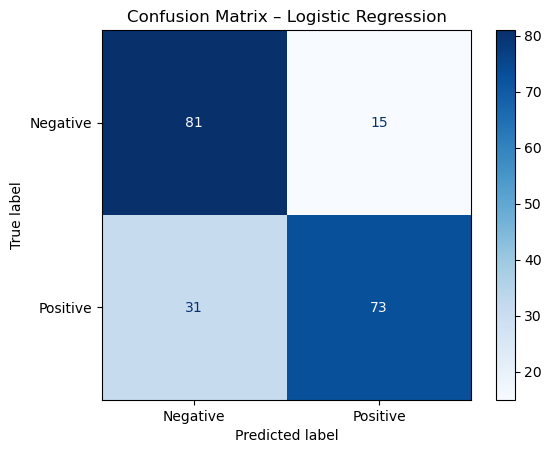


 Naive Bayes Classification Report
----------------------------------------
              precision    recall  f1-score   support

           0       0.74      0.74      0.74        96
           1       0.76      0.76      0.76       104

    accuracy                           0.75       200
   macro avg       0.75      0.75      0.75       200
weighted avg       0.75      0.75      0.75       200

 Accuracy: 0.7500


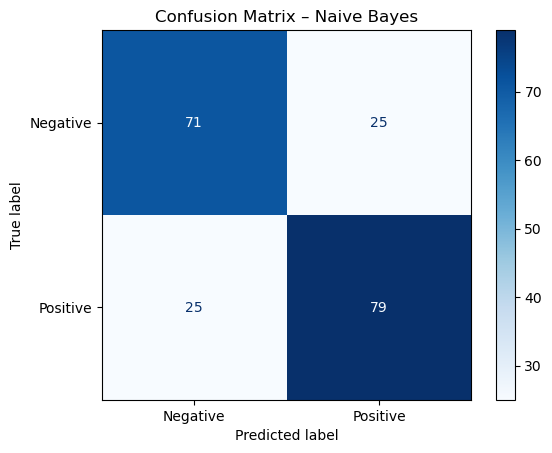


 XGBoost Classification Report
----------------------------------------
              precision    recall  f1-score   support

           0       0.63      0.86      0.73        96
           1       0.81      0.54      0.65       104

    accuracy                           0.69       200
   macro avg       0.72      0.70      0.69       200
weighted avg       0.73      0.69      0.69       200

 Accuracy: 0.6950


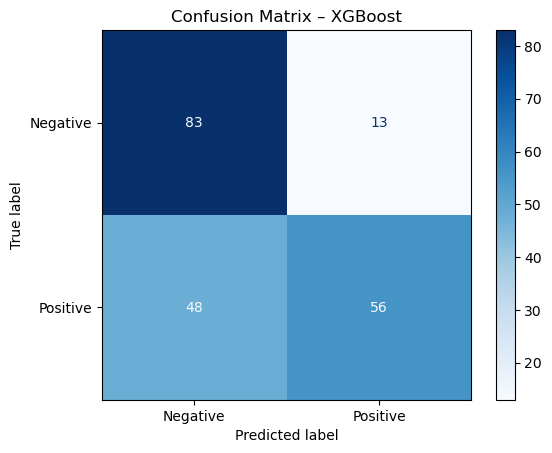

In [18]:
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    print(f"\n {name} Classification Report")
    print("-" * 40)
    print(classification_report(y_test, y_pred))

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    results[name] = {"Accuracy": acc}
    print(f" Accuracy: {acc:.4f}")

    # store classification report in each variable for Fine-Tuned vs Classical comparison

    if name == "Logistic Regression":
        logistic_accuracy = acc
        logistic_precision = prec
        logistic_recall = rec
        logistic_f1 = f1

    elif name == "Naive Bayes":
        naivebayes_accuracy = acc
        naivebayes_precision = prec
        naivebayes_recall = rec
        naivebayes_f1 = f1

    elif name == "XGBoost":
        xgboost_accuracy = acc
        xgboost_precision = prec
        xgboost_recall = rec
        xgboost_f1 = f1

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])
    disp.plot(cmap="Blues", values_format='d')
    plt.title(f"Confusion Matrix – {name}")
    plt.grid(False)
    plt.show()

### GridSearch for SVM


 Tuning Support Vector Machine (SVM)...

 Tuned SVM Classification Report
----------------------------------------
              precision    recall  f1-score   support

           0       0.73      0.80      0.76        96
           1       0.80      0.72      0.76       104

    accuracy                           0.76       200
   macro avg       0.76      0.76      0.76       200
weighted avg       0.76      0.76      0.76       200

Best SVM Parameters: {'C': 1, 'max_iter': 1000}
 Accuracy: 0.7600


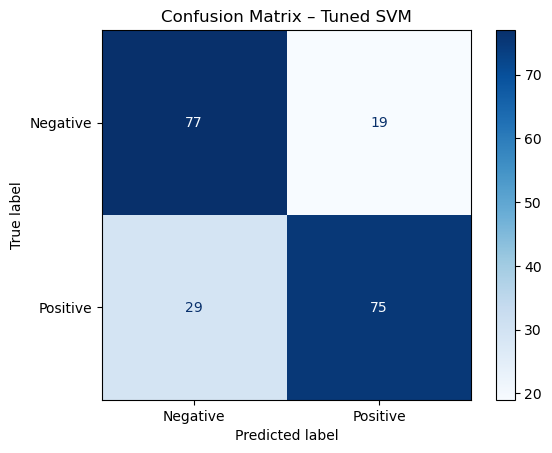

In [19]:
print("\n Tuning Support Vector Machine (SVM)...")
svm_param_grid = {'C': [0.1, 1, 10], 'max_iter': [1000, 2000]}
svm_grid = GridSearchCV(LinearSVC(), svm_param_grid, cv=3, n_jobs=-1)
svm_grid.fit(X_train, y_train)
best_svm = svm_grid.best_estimator_
y_pred_svm = best_svm.predict(X_test)

print("\n Tuned SVM Classification Report")
print("-" * 40)
print(classification_report(y_test, y_pred_svm))
print("Best SVM Parameters:", svm_grid.best_params_)
accuracy_svm_grid = accuracy_score(y_test, y_pred_svm)
results["Tuned SVM"] = {"Accuracy": accuracy_svm_grid}
print(f" Accuracy: {accuracy_svm_grid:.4f}")
precision_svm_grid = precision_score(y_test,y_pred_svm)
f1_svm_grid = f1_score(y_test,y_pred_svm)
recall_svm_grid = recall_score(y_test,y_pred_svm)


cm_svm = confusion_matrix(y_test, y_pred_svm, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_svm, display_labels=["Negative", "Positive"])
disp.plot(cmap="Blues", values_format='d')
plt.title("Confusion Matrix – Tuned SVM")
plt.grid(False)
plt.show()

### GridSearch for Random Forest


 Tuning Random Forest...

 Tuned Random Forest Classification Report
----------------------------------------
              precision    recall  f1-score   support

           0       0.63      0.86      0.73        96
           1       0.81      0.54      0.65       104

    accuracy                           0.69       200
   macro avg       0.72      0.70      0.69       200
weighted avg       0.73      0.69      0.69       200

Best RF Parameters: {'max_depth': None, 'min_samples_split': 5, 'n_estimators': 100}
 Accuracy: 0.6950


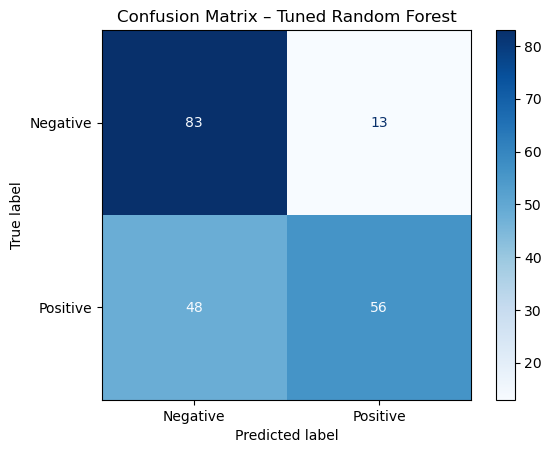

In [20]:
print("\n Tuning Random Forest...")
rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5]
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_param_grid, cv=3, n_jobs=-1)
rf_grid.fit(X_train, y_train)
best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test)

print("\n Tuned Random Forest Classification Report")
print("-" * 40)
print(classification_report(y_test, y_pred_rf))
print("Best RF Parameters:", rf_grid.best_params_)
accuracy_rf_grid = accuracy_score(y_test, y_pred_rf)
results["Tuned Random Forest"] = {"Accuracy": accuracy_rf_grid}
print(f" Accuracy: {accuracy_rf_grid:.4f}")
precision_rf_grid = precision_score(y_test,y_pred_rf)
f1_rf_grid = f1_score(y_test,y_pred_rf)
recall_rf_grid = recall_score(y_test,y_pred_rf)


cm_rf = confusion_matrix(y_test, y_pred_rf, labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=["Negative", "Positive"])
disp.plot(cmap="Blues", values_format='d')
plt.title("Confusion Matrix – Tuned Random Forest")
plt.grid(False)
plt.show()

### Classification Comparison Chart

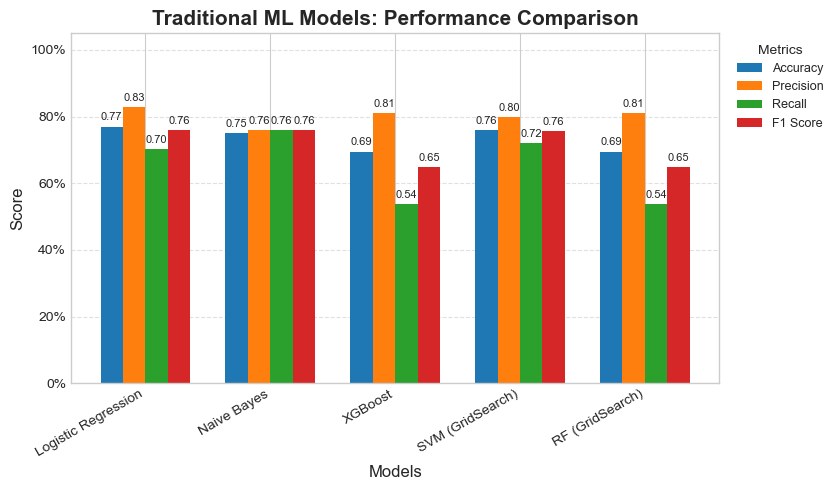

In [21]:
models = [
    "Logistic Regression", "Naive Bayes", "XGBoost",
    "SVM (GridSearch)", "RF (GridSearch)"
]

metrics = {
    "Accuracy": [
        logistic_accuracy, naivebayes_accuracy, xgboost_accuracy,
        accuracy_svm_grid, accuracy_rf_grid
    ],
    "Precision": [
        logistic_precision, naivebayes_precision, xgboost_precision,
        precision_svm_grid, precision_rf_grid
    ],
    "Recall": [
        logistic_recall, naivebayes_recall, xgboost_recall,
        recall_svm_grid, recall_rf_grid
    ],
    "F1 Score": [
        logistic_f1, naivebayes_f1, xgboost_f1,
        f1_svm_grid, f1_rf_grid
    ]
}

x = np.arange(len(models))
width = 0.18
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']  # Consistent and clear

plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(10, 5))  # Slightly smaller for 5 models

for i, (metric_name, values) in enumerate(metrics.items()):
    offset = (i - 1.5) * width
    bars = ax.bar(x + offset, values, width, label=metric_name, color=colors[i])

    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=8)

ax.set_ylabel('Score', fontsize=12)
ax.set_xlabel('Models', fontsize=12)
ax.set_title('Traditional ML Models: Performance Comparison', fontsize=15, weight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=30, ha='right', fontsize=10)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

ax.legend(title='Metrics', fontsize=9, title_fontsize=10, loc='upper left', bbox_to_anchor=(1.01, 1))
ax.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

# TASK - 3 Perform classification using a BERT- Fine Tuning

### Combine final cleaned text with labels

In [22]:
df_bert = pd.DataFrame({'text': final_cleaned, 'label': df['label']})

train_texts, test_texts, train_labels, test_labels = train_test_split(
    df_bert['text'].tolist(), df_bert['label'].tolist(), test_size=0.2, random_state=42
)

### BERT Tokenizer

In [23]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

train_encodings = tokenizer(train_texts, truncation=True, padding=True, max_length=128)
test_encodings = tokenizer(test_texts, truncation=True, padding=True, max_length=128)

In [24]:
class YelpDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels
    def __getitem__(self, idx):
        return {key: torch.tensor(val[idx]) for key, val in self.encodings.items()} | {'labels': torch.tensor(self.labels[idx])}
    def __len__(self):
        return len(self.labels)

train_dataset = YelpDataset(train_encodings, train_labels)
test_dataset = YelpDataset(test_encodings, test_labels)

### BERT Fine-Tuning Model

In [25]:
bert_model = BertForSequenceClassification.from_pretrained("bert-base-uncased", num_labels=2)

training_args = TrainingArguments(
    output_dir="./results",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    logging_dir="./logs",
    logging_steps=10
)

Some weights of BertForSequenceClassification were not initialized from the model checkpoint at bert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [26]:
def compute_metrics(pred):
    labels = pred.label_ids
    preds = pred.predictions.argmax(-1)
    acc = accuracy_score(labels, preds)
    return {"accuracy": acc}

### Create Trainer

In [27]:
trainer = Trainer(
    model=bert_model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset,
    compute_metrics=compute_metrics
)

### BERT Fine-Tuning Training

In [28]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.452000,0.453266,0.820000
2,0.234200,0.360145,0.850000
3,0.092300,0.405207,0.870000


TrainOutput(global_step=150, training_loss=0.34739349524180096, metrics={'train_runtime': 64.295, 'train_samples_per_second': 37.328, 'train_steps_per_second': 2.333, 'total_flos': 32066659872000.0, 'train_loss': 0.34739349524180096, 'epoch': 3.0})

### Evaluation

In [29]:
eval_result = trainer.evaluate()
run_time_bert = eval_result['eval_runtime']
accuracy_bert = eval_result['eval_accuracy']
results["BERT Fine-Tuned"] = {"Accuracy": accuracy_bert}
print(f"\n BERT Accuracy: {eval_result['eval_accuracy']:.4f}")


 BERT Accuracy: 0.8700


### Classification Report and Confusion Matrix of BERT Fine-Tuning

Classification Report for BERT Fine-Tuning:

              precision    recall  f1-score   support

    Negative       0.86      0.86      0.86        96
    Positive       0.88      0.88      0.88       104

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



<Figure size 600x400 with 0 Axes>

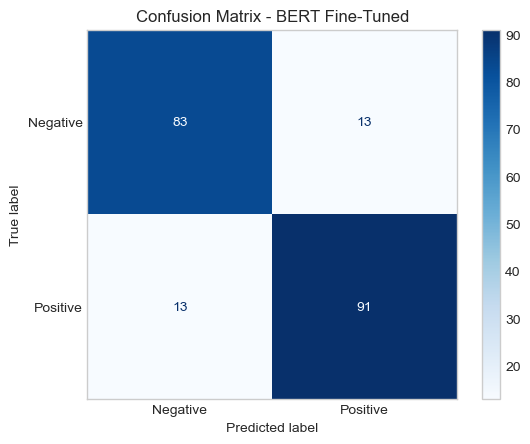

In [30]:
preds_output = trainer.predict(test_dataset)
y_pred = preds_output.predictions.argmax(-1)
y_true = preds_output.label_ids

print("Classification Report for BERT Fine-Tuning:\n")
print(classification_report(y_true, y_pred, target_names=["Negative", "Positive"]))
precision_bert = precision_score(y_true,y_pred)
f1_bert = f1_score(y_true,y_pred)
recall_bert = recall_score(y_true,y_pred)

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])

plt.figure(figsize=(6, 4))
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix - BERT Fine-Tuned")
plt.grid(False)
plt.show()

### Save BERT Fine-Tuned model and tokenizer for future use

In [31]:
# Save model and tokenizer
trainer.save_model("./bert_saved_model")
tokenizer.save_pretrained("./bert_saved_model")

# Cleanup (free memory)
del trainer
del bert_model
del train_dataset, test_dataset
del train_encodings, test_encodings

# Clear CUDA cache (if using GPU)
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Force garbage collection
gc.collect()

4582

# DistilBERT Fine-Tuning

### Tokenization DistilBERT

In [32]:
distil_tokenizer = DistilBertTokenizerFast.from_pretrained('distilbert-base-uncased')
train_encodings_distil = distil_tokenizer(train_texts, truncation=True, padding=True, max_length=128)
test_encodings_distil = distil_tokenizer(test_texts, truncation=True, padding=True, max_length=128)

In [33]:
train_dataset_distil = YelpDataset(train_encodings_distil, train_labels)
test_dataset_distil = YelpDataset(test_encodings_distil, test_labels)

### DistilBERT model

In [34]:
distil_model = DistilBertForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=2)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [35]:
distil_training_args = TrainingArguments(
    output_dir="./results_distil",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    logging_dir="./logs_distil",
    logging_steps=10
)

### Create Trainer

In [36]:
distil_trainer = Trainer(
    model=distil_model,
    args=distil_training_args,
    train_dataset=train_dataset_distil,
    eval_dataset=test_dataset_distil,
    compute_metrics=compute_metrics
)

### DistilBERT Fine-Tuning Training

In [37]:
distil_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.435700,0.496074,0.805000
2,0.164200,0.590135,0.765000
3,0.090200,0.595978,0.795000


TrainOutput(global_step=150, training_loss=0.3177455910046895, metrics={'train_runtime': 35.1508, 'train_samples_per_second': 68.277, 'train_steps_per_second': 4.267, 'total_flos': 16144464211200.0, 'train_loss': 0.3177455910046895, 'epoch': 3.0})

### Evaluation

In [38]:
distil_eval_result = distil_trainer.evaluate()
run_time_distil = distil_eval_result['eval_runtime']
distil_acc = distil_eval_result['eval_accuracy']
results["DistilBERT Fine-Tuned"] = {"Accuracy": distil_acc}
print(f"\n DistilBERT Accuracy: {distil_eval_result['eval_accuracy']:.4f}")


 DistilBERT Accuracy: 0.7950


### Classification Report and confusion matrix of DistilBERT Fine-Tuning

Classification Report for DistilBERT Fine-Tuning:

              precision    recall  f1-score   support

    Negative       0.76      0.83      0.80        96
    Positive       0.83      0.76      0.79       104

    accuracy                           0.80       200
   macro avg       0.80      0.80      0.79       200
weighted avg       0.80      0.80      0.79       200



<Figure size 600x400 with 0 Axes>

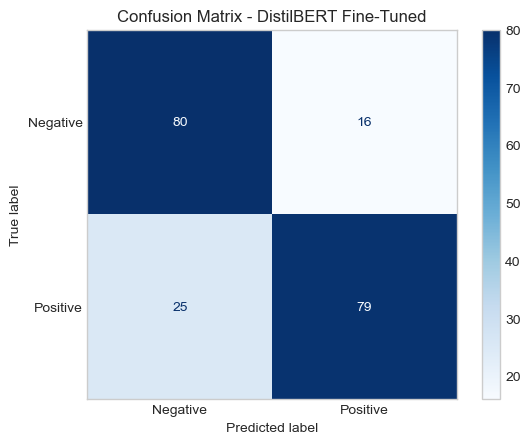

In [39]:
distil_preds_output = distil_trainer.predict(test_dataset_distil)
y_pred_distil = distil_preds_output.predictions.argmax(-1)
y_true_distil = distil_preds_output.label_ids

print("Classification Report for DistilBERT Fine-Tuning:\n")
print(classification_report(y_true_distil, y_pred_distil, target_names=["Negative", "Positive"]))
precision_distil = precision_score(y_true_distil,y_pred_distil)
f1_distil = f1_score(y_true_distil,y_pred_distil)
recall_distil = recall_score(y_true_distil,y_pred_distil)

cm = confusion_matrix(y_true_distil, y_pred_distil)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])

plt.figure(figsize=(6, 4))
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix - DistilBERT Fine-Tuned")
plt.grid(False)
plt.show()

### Save DistilBERT Fine-Tuned model and tokenizer for future use

In [40]:
distil_trainer.save_model("./distilbert_saved_model")
distil_tokenizer.save_pretrained("./distilbert_saved_model")

del distil_trainer
del distil_model
del train_dataset_distil, test_dataset_distil
del train_encodings_distil, test_encodings_distil

if torch.cuda.is_available():
    torch.cuda.empty_cache()

gc.collect()

4775

# RoBERTa Fine-Tuning

### Tokenization RoBERTa

In [41]:
roberta_tokenizer = RobertaTokenizerFast.from_pretrained('roberta-base')
train_encodings_roberta = roberta_tokenizer(train_texts, truncation=True, padding=True, max_length=128)
test_encodings_roberta = roberta_tokenizer(test_texts, truncation=True, padding=True, max_length=128)

In [42]:
train_dataset_roberta = YelpDataset(train_encodings_roberta, train_labels)
test_dataset_roberta = YelpDataset(test_encodings_roberta, test_labels)

### RoBERTa Model

In [43]:
roberta_model = RobertaForSequenceClassification.from_pretrained("roberta-base", num_labels=2)

if torch.cuda.is_available():
    torch.cuda.empty_cache()

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at roberta-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


In [44]:
roberta_training_args = TrainingArguments(
    output_dir="./results_roberta",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=64,
    eval_strategy="epoch",
    logging_dir="./logs_roberta",
    logging_steps=10
)

### Create Trainer

In [45]:
roberta_trainer = Trainer(
    model=roberta_model,
    args=roberta_training_args,
    train_dataset=train_dataset_roberta,
    eval_dataset=test_dataset_roberta,
    compute_metrics=lambda pred: {"accuracy": accuracy_score(pred.label_ids, pred.predictions.argmax(-1))}
)

### RoBERTa Fine-Tuning Training

In [46]:
roberta_trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.508800,0.536549,0.800000
2,0.314000,0.388868,0.830000
3,0.121400,0.462086,0.870000


TrainOutput(global_step=150, training_loss=0.38402488867441814, metrics={'train_runtime': 66.1169, 'train_samples_per_second': 36.299, 'train_steps_per_second': 2.269, 'total_flos': 29599993728000.0, 'train_loss': 0.38402488867441814, 'epoch': 3.0})

### Evaluation of RoBERTa

In [47]:
roberta_eval_result = roberta_trainer.evaluate()
run_time_roberta = roberta_eval_result['eval_runtime']
roberta_acc = roberta_eval_result['eval_accuracy']
results["RoBERTa Fine-Tuned"] = {"Accuracy": roberta_acc}
print(f"\n RoBERTa Accuracy: {roberta_eval_result['eval_accuracy']:.4f}")


 RoBERTa Accuracy: 0.8700


### Classsification report and Tokenizer of RoBERTa Fine-Tuning

Classification Report for RoBERTa Fine-Tuning:

              precision    recall  f1-score   support

    Negative       0.85      0.89      0.87        96
    Positive       0.89      0.86      0.87       104

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200



<Figure size 600x400 with 0 Axes>

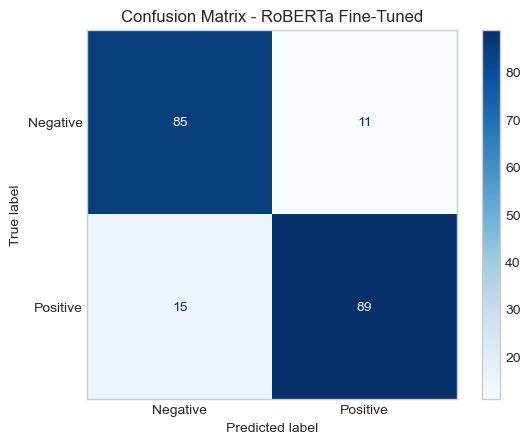

In [48]:
roberta_preds_output = roberta_trainer.predict(test_dataset_roberta)
y_pred_roberta = roberta_preds_output.predictions.argmax(-1)
y_true_roberta = roberta_preds_output.label_ids

print("Classification Report for RoBERTa Fine-Tuning:\n")
print(classification_report(y_true_roberta, y_pred_roberta, target_names=["Negative", "Positive"]))
precision_roberta = precision_score(y_true_roberta,y_pred_roberta)
f1_roberta = f1_score(y_true_roberta,y_pred_roberta)
recall_roberta = recall_score(y_true_roberta,y_pred_roberta)

cm = confusion_matrix(y_true_roberta, y_pred_roberta)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Negative", "Positive"])

plt.figure(figsize=(6, 4))
disp.plot(cmap=plt.cm.Blues, values_format='d')
plt.title("Confusion Matrix - RoBERTa Fine-Tuned")
plt.grid(False)
plt.show()

### Save RoBERTa Fine-Tuned model and tokenizer for future use

In [49]:
roberta_trainer.save_model("./roberta_saved_model")
roberta_tokenizer.save_pretrained("./roberta_saved_model")

del roberta_trainer
del roberta_model
del train_dataset_roberta, test_dataset_roberta
del train_encodings_roberta, test_encodings_roberta

if torch.cuda.is_available():
    torch.cuda.empty_cache()

gc.collect()

4497

# Model Comparison: Classical ML vs Fine-Tuned Transformers

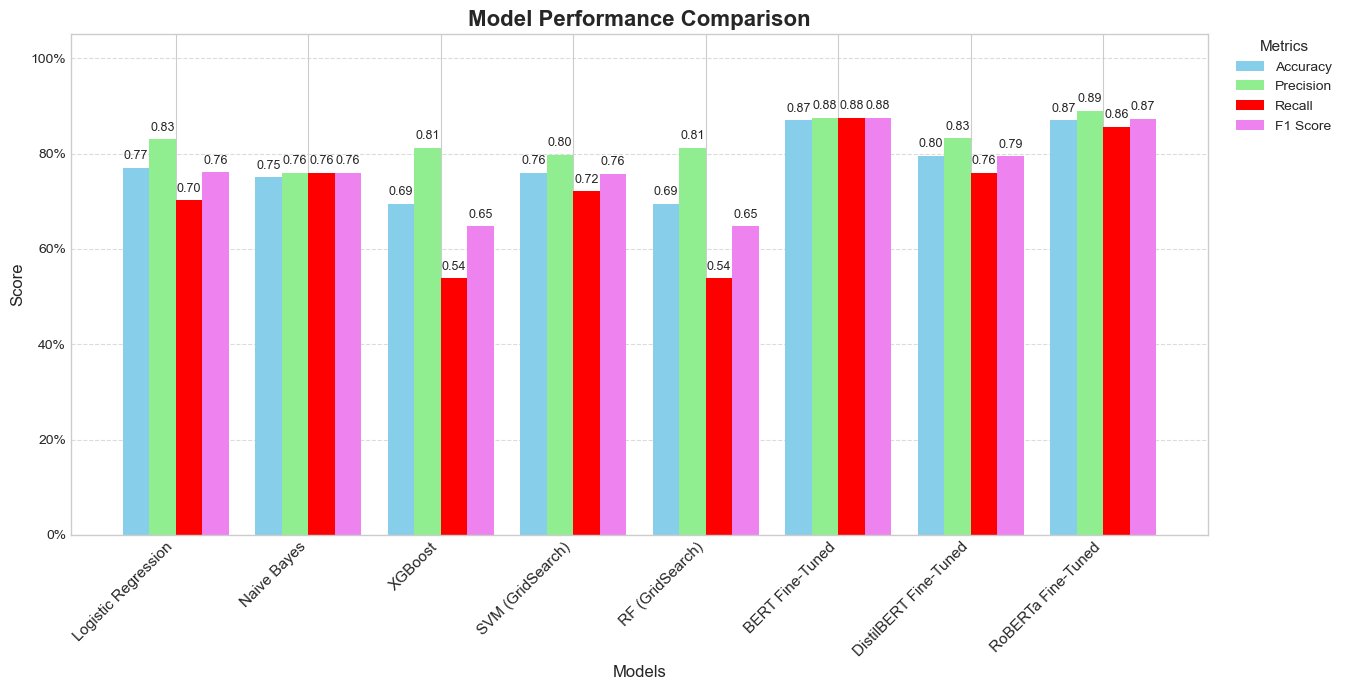

In [50]:
models = [
    "Logistic Regression", "Naive Bayes", "XGBoost", "SVM (GridSearch)",
    "RF (GridSearch)", "BERT Fine-Tuned", "DistilBERT Fine-Tuned", "RoBERTa Fine-Tuned"
]

metrics = {
    "Accuracy": [
        logistic_accuracy, naivebayes_accuracy, xgboost_accuracy, accuracy_svm_grid,
        accuracy_rf_grid, accuracy_bert, distil_acc, roberta_acc
    ],
    "Precision": [
        logistic_precision, naivebayes_precision, xgboost_precision, precision_svm_grid,
        precision_rf_grid, precision_bert, precision_distil, precision_roberta
    ],
    "Recall": [
        logistic_recall, naivebayes_recall, xgboost_recall, recall_svm_grid,
        recall_rf_grid, recall_bert, recall_distil, recall_roberta
    ],
    "F1 Score": [
        logistic_f1, naivebayes_f1, xgboost_f1, f1_svm_grid,
        f1_rf_grid, f1_bert, f1_distil, f1_roberta
    ]
}

x = np.arange(len(models))
width = 0.2
colors = ['skyblue', 'lightgreen', 'red', 'violet']
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(16, 7))

for i, (metric_name, values) in enumerate(metrics.items()):
    bars = ax.bar(x + (i - 1.5) * width, values, width, label=metric_name, color=colors[i])
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f'{height:.2f}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 4),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

ax.set_ylabel('Score', fontsize=12)
ax.set_xlabel('Models', fontsize=12)
ax.set_title('Model Performance Comparison', fontsize=16, weight='bold')
ax.set_xticks(x)
ax.set_xticklabels(models, rotation=45, ha='right', fontsize=11)
ax.set_ylim(0, 1.05)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.grid(True, axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Metrics', fontsize=10, title_fontsize=11,
          bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.show()

### Transformer Models Accuracy vs Run time

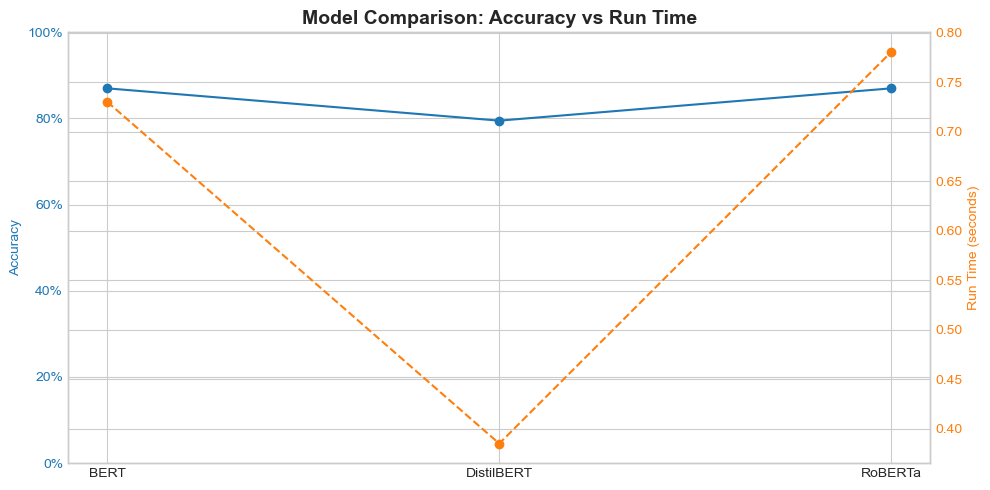

In [51]:
models = ["BERT", "DistilBERT", "RoBERTa"]
accuracies = [accuracy_bert, distil_acc, roberta_acc]
runtimes = [run_time_bert, run_time_distil, run_time_roberta]

fig, ax1 = plt.subplots(figsize=(10, 5))

ax1.plot(models, accuracies, 'o-', color="#1f77b4", label='Accuracy')
ax1.set_ylabel('Accuracy', color='#1f77b4')
ax1.set_ylim(0, 1)
ax1.tick_params(axis='y', labelcolor='#1f77b4')
ax1.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))

ax2 = ax1.twinx()
ax2.plot(models, runtimes, 'o--', color="#ff7f0e", label='Run Time')
ax2.set_ylabel('Run Time (seconds)', color='#ff7f0e')
ax2.tick_params(axis='y', labelcolor='#ff7f0e')

plt.title("Model Comparison: Accuracy vs Run Time", fontsize=14, weight='bold')
plt.tight_layout()
plt.show()

# TASK - 4 Topic Detection

### CountVectorizer for LDA

In [52]:
count_vectorizer = CountVectorizer(max_df=0.95, min_df=2, stop_words='english')
count_dtm = count_vectorizer.fit_transform(final_cleaned)

### TfidfVectorizer for NMF

In [53]:
tfidf_vectorizer = TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')
tfidf = tfidf_vectorizer.fit_transform(final_cleaned)

### TfidfVectorizer for LSA

In [54]:
vectorizer = TfidfVectorizer(max_df=0.95, min_df=2, stop_words='english')
tfidf = vectorizer.fit_transform(final_cleaned)
feature_names = vectorizer.get_feature_names_out()

### Train the Topic Models

### LDA

In [55]:
lda_model = LatentDirichletAllocation(n_components=20, random_state=42)
lda_model.fit(count_dtm)

LatentDirichletAllocation(n_components=20, random_state=42)

### NMF

In [56]:
nmf_model = NMF(n_components=20, random_state=42)
nmf_model.fit(tfidf)

NMF(n_components=20, random_state=42)

### LSA

In [57]:
lsa_model = TruncatedSVD(n_components=20, random_state=42)
lsa_model.fit(tfidf)

TruncatedSVD(n_components=20, random_state=42)

### Top Words per Topic

In [58]:
def get_topics(model, feature_names, top_n=20):
    topics = []
    for idx, topic in enumerate(model.components_):
        # Get indices of top_n words in the topic (descending order)
        top_words = [feature_names[i] for i in topic.argsort()[:-top_n - 1:-1]]
        topics.append((f"Topic {idx + 1}", top_words))
    return topics

lsa_topics = get_topics(lsa_model, tfidf_vectorizer.get_feature_names_out(), top_n=20)
nmf_topics = get_topics(nmf_model, tfidf_vectorizer.get_feature_names_out(), top_n=20)
lda_topics = get_topics(lda_model, count_vectorizer.get_feature_names_out(), top_n=20)

In [59]:
print("\n--- LDA Topics ---\n")
for topic, words in lda_topics:
    print(f"{topic}: {' | '.join(words)}")

print("\n--- NMF Topics ---\n")
for topic, words in nmf_topics:
    print(f"{topic}: {' | '.join(words)}")

print("\n--- LSA Topics ---\n")
for topic, words in lsa_topics:
    print(f"{topic}: {' | '.join(words)}")


--- LDA Topics ---

Topic 1: way | cold | overpriced | chicken | friend | special | hot | barely | like | good | food | dish | salad | perfect | damn | bad | feel | fried | dressing | greek
Topic 2: really | experience | place | good | great | know | food | atmosphere | hour | seriously | need | menu | establishment | definitely | fish | overpriced | pizza | got | like | long
Topic 3: place | like | eat | sushi | great | love | time | want | restaurant | good | vega | avoid | authentic | healthy | steak | cooked | better | potato | believe | party
Topic 4: night | come | review | right | rude | fry | burger | got | place | asked | management | disappointment | perfect | seated | really | vega | came | time | eating | away
Topic 5: going | soon | getting | anytime | say | try | pretty | think | food | seafood | tasteless | felt | insulted | taste | like | place | portion | generous | disrespected | gross
Topic 6: time | food | good | best | buffet | vega | breakfast | tasty | check | w

### Plot Top 5 Topics from Each Model

In [60]:
def plot_top_words(model, feature_names=None, n_top_words=10, n_topics=5, model_type='lsa'):
    print(f"\n Plotting {n_topics} Topics from {model_type.upper()}...\n")

    if model_type in ['lsa', 'nmf', 'lda']:  # all sklearn models
        for topic_idx in range(n_topics):
            topic = model.components_[topic_idx]
            top_indices = topic.argsort()[:-n_top_words - 1:-1]
            top_words = [feature_names[i] for i in top_indices]
            top_scores = topic[top_indices]

            plt.figure(figsize=(10, 5))
            sns.barplot(x=top_scores, y=top_words, palette='crest',hue=top_words)
            plt.title(f"{model_type.upper()} Topic #{topic_idx + 1}")
            plt.xlabel("Word Importance")
            plt.ylabel("Top Words")
            plt.tight_layout()
            plt.show()


 Plotting 5 Topics from LDA...



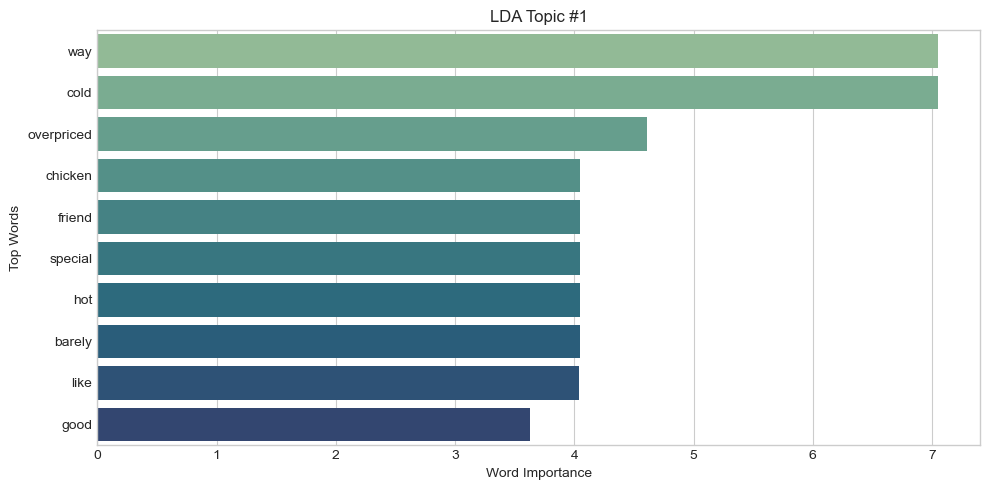

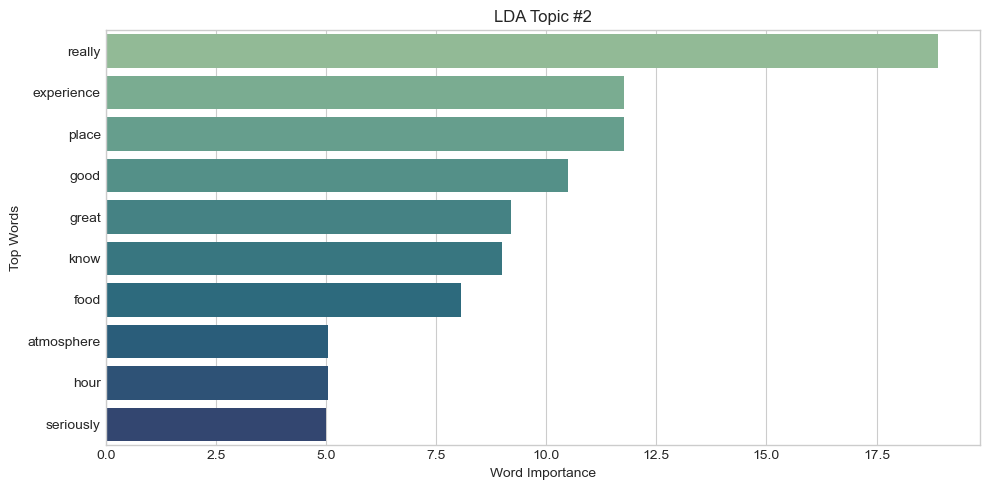

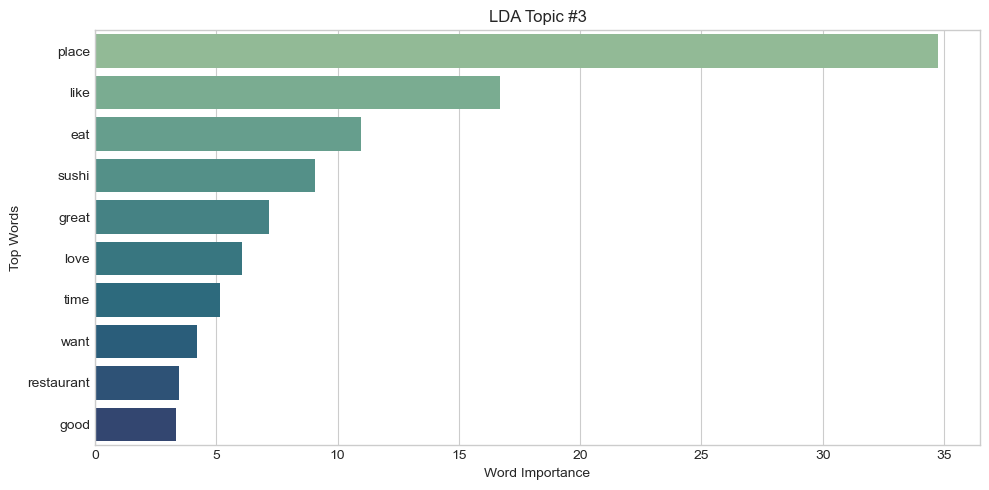

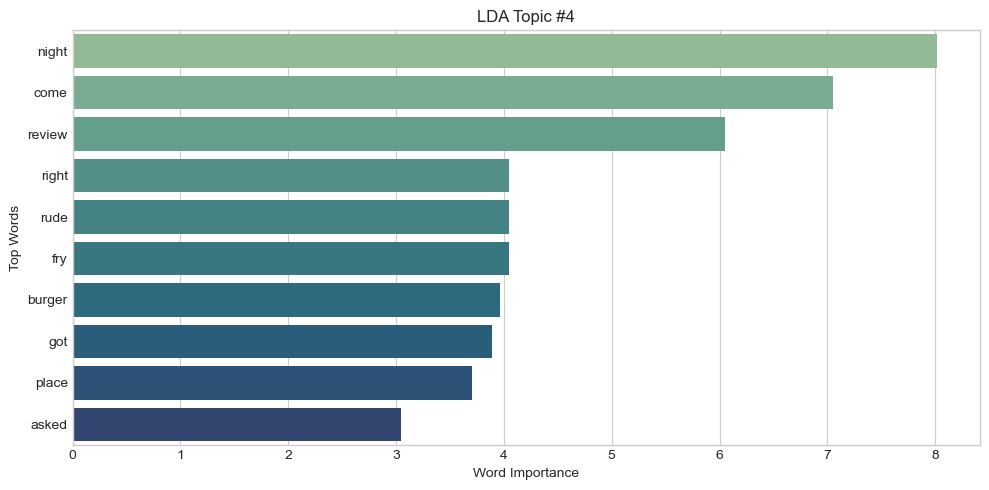

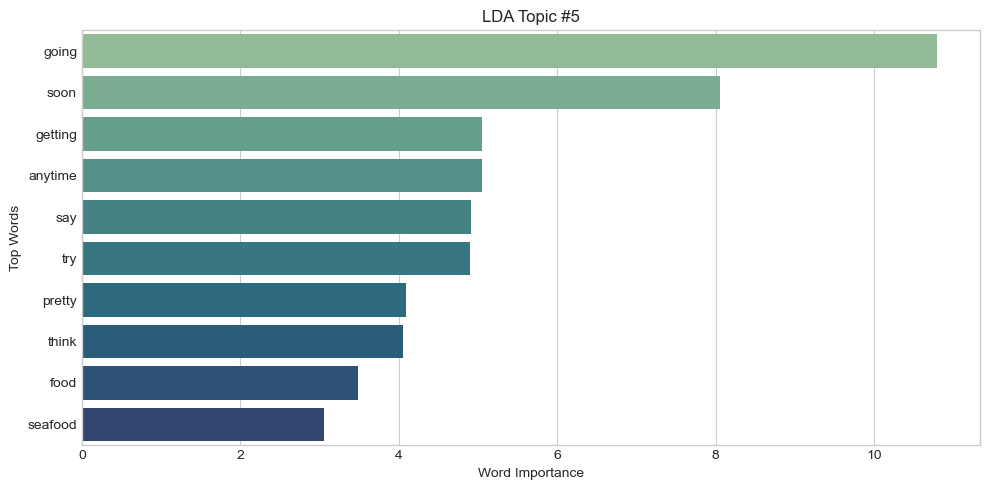

In [61]:
plot_top_words(lda_model, feature_names=feature_names, model_type='lda')


 Plotting 5 Topics from NMF...



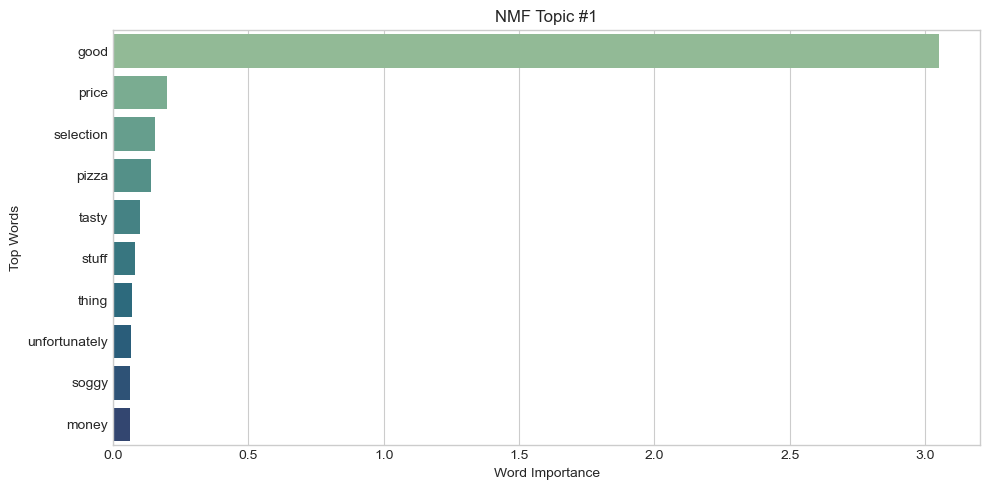

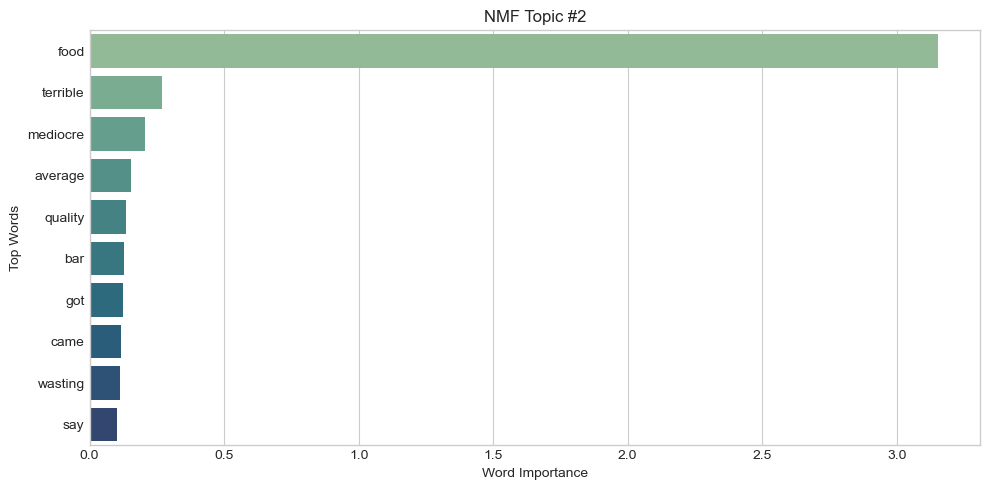

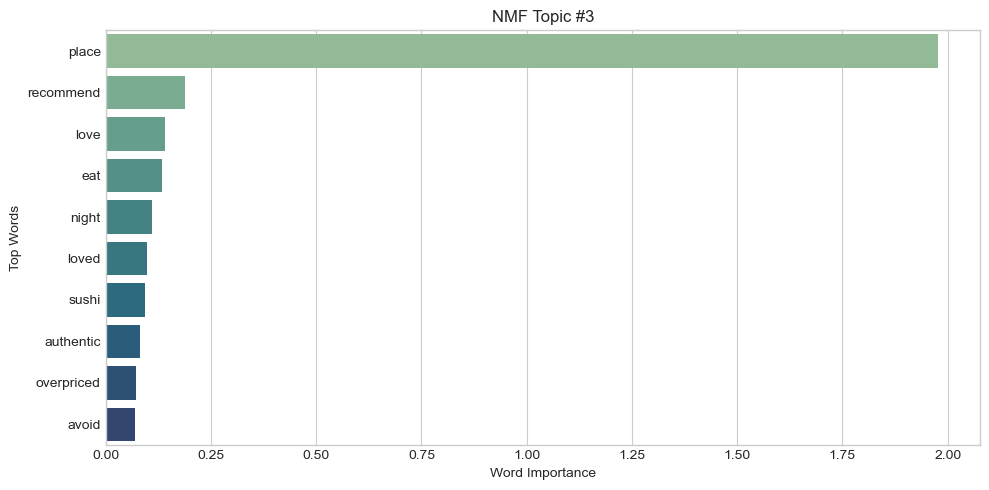

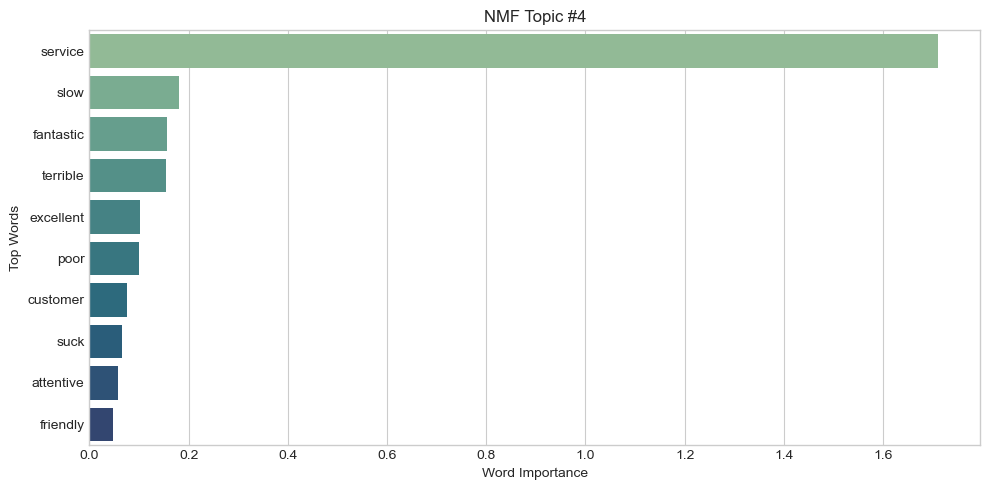

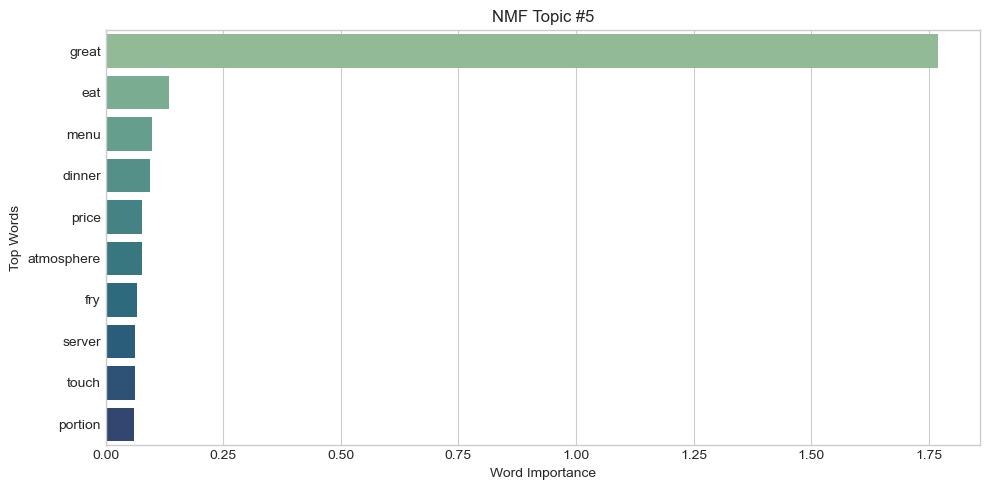

In [62]:
plot_top_words(nmf_model, feature_names=feature_names, model_type='nmf')


 Plotting 5 Topics from LSA...



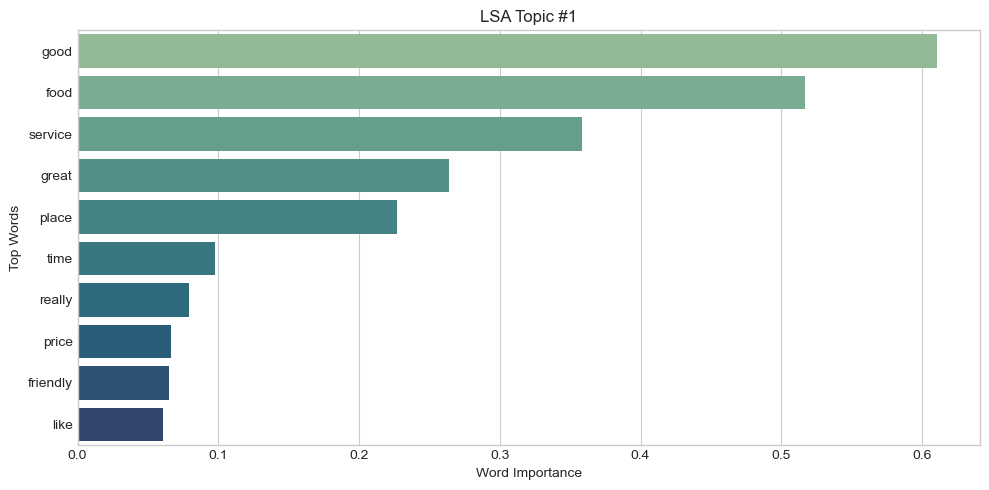

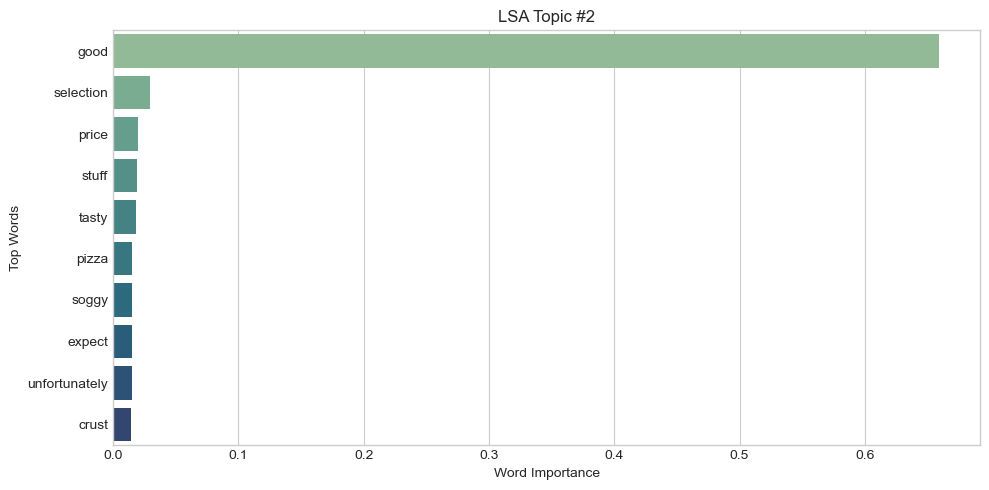

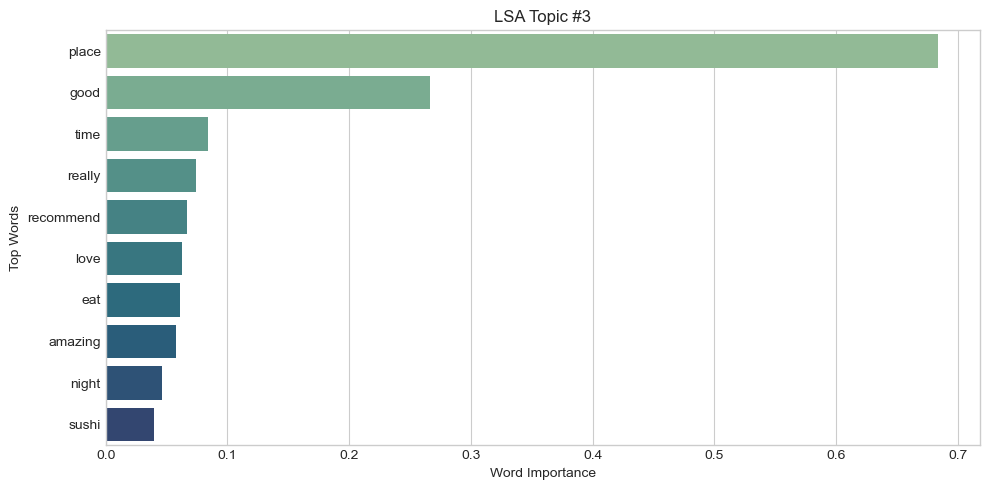

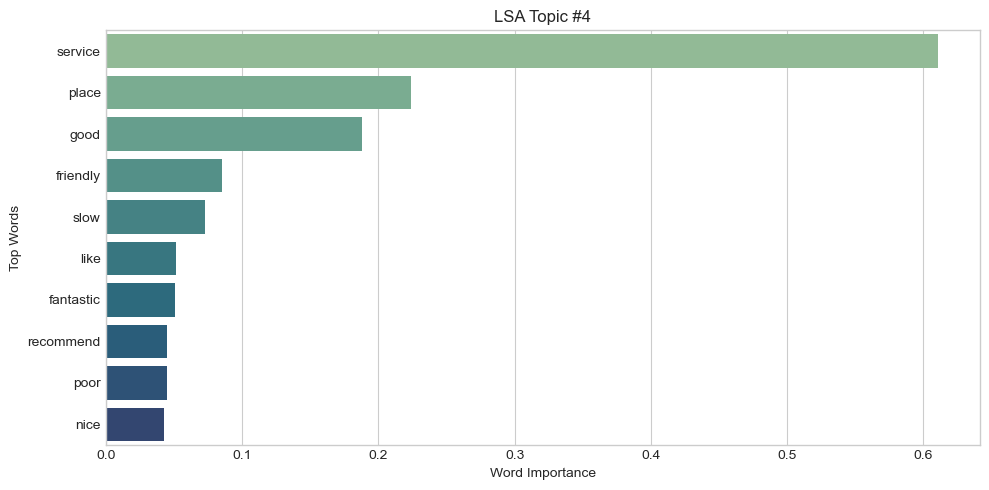

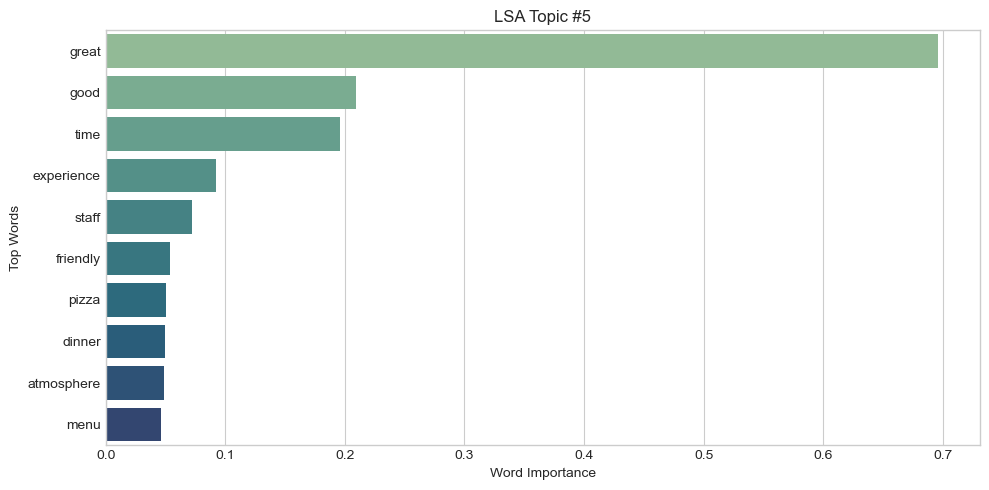

In [63]:
plot_top_words(lsa_model, feature_names=feature_names, model_type='lsa')

### Find dominant topic index for each document (row) & Document Clusters in LSA Topic Space 

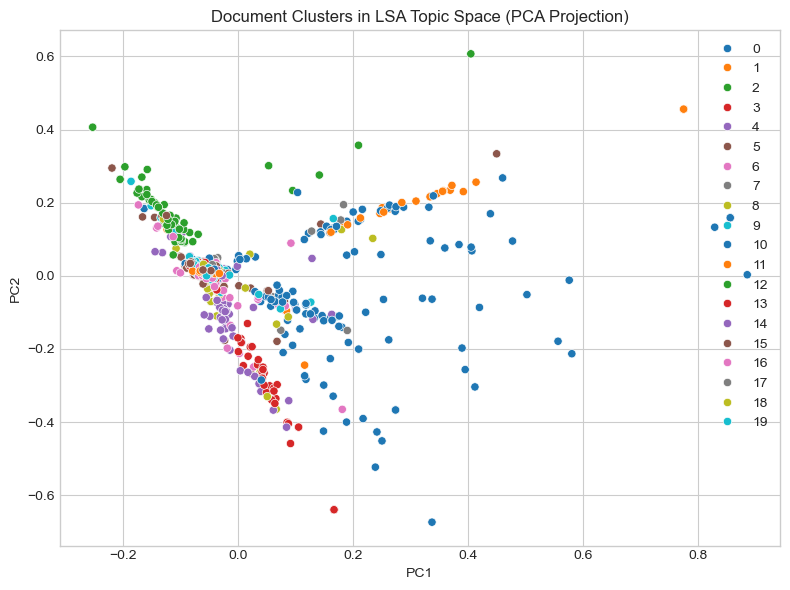

In [64]:
lsa_topic_matrix = lsa_model.transform(tfidf)
dominant_topics = lsa_topic_matrix.argmax(axis=1)
pca = PCA(n_components=2)
coords = pca.fit_transform(lsa_topic_matrix)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=dominant_topics, palette='tab10', legend="full")
plt.title("Document Clusters in LSA Topic Space (PCA Projection)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.tight_layout()
plt.show()